# Worst-Case Portfolio Loss Probability via Linear Programming

## Abstract
Assessing portfolio risk by relying solely on joint normality assumptions can severely underestimate tail risk. This note investigates the worst-case probability of loss for a two-asset portfolio given known Gaussian marginal distributions and a specified correlation matrix. By discretizing the return space and treating the joint probability distribution as a decision variable, we cast the worst-case risk assessment as a Linear Programming (LP) problem.

## Problem Formulation
We seek a joint probability mass matrix $P \in \mathbf{R}^{n \times n}$ that maximizes the probability of a negative portfolio return (i.e., $R_1 + R_2 \le 0$). Let $M \in \mathbf{R}^{n \times n}$ be the deviation matrix where $M_{ij} = (r_i - \mu_1)(r_j - \mu_2)$, and let $C \in \mathbf{R}^{n \times n}$ be an indicator matrix where $C_{ij} = 1$ if $r_i + r_j \le 0$ and $0$ otherwise.

Maximize:
$$\sum_{i=1}^n \sum_{j=1}^n P_{ij} C_{ij}$$

Subject to:
$$P_{ij} \ge 0$$
$$\sum_{j=1}^n P_{ij} = p^{(1)}_i, \quad \sum_{i=1}^n P_{ij} = p^{(2)}_j$$
$$\sum_{i=1}^n \sum_{j=1}^n P_{ij} M_{ij} = \rho \sigma_1 \sigma_2$$

In [2]:
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.stats import norm, multivariate_normal
from src.portfolio_tail_risk import optimize_worst_case_copula

mu = (5.0, 15.0)
sigma = (3.0, 10.0)
rho = -0.3
n = 100
r = np.linspace(-20, 50, n)

Below we create the marginals of the discrete distrubution:

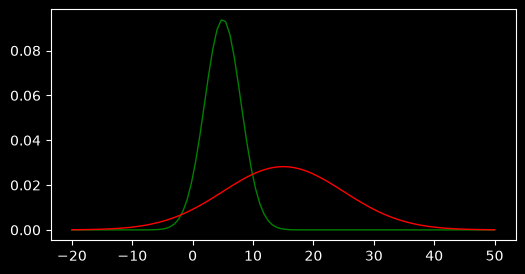

In [3]:
results = optimize_worst_case_copula(mu_vec=mu, sigma_vec=sigma, rho=rho, grid_size=n)
p_mar = results["marginals"]

plt.rcParams['figure.figsize'] = [6, 3]
fig = plt.figure()
plt.plot(r, p_mar[0], 'g', linewidth=1)
plt.plot(r, p_mar[1], 'r', linewidth=1)
plt.show()

Let's also draw the joint Gaussian distribution.

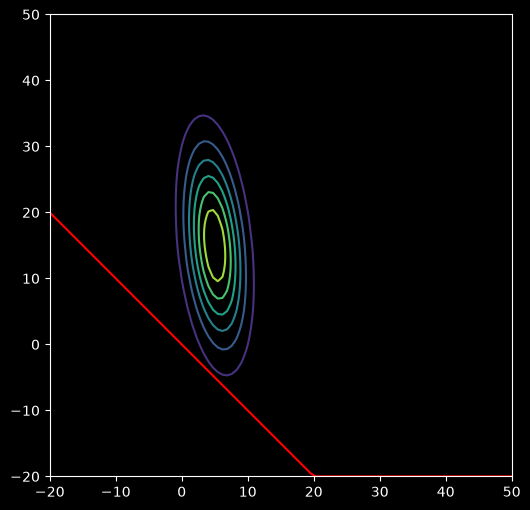

In [4]:
cov = np.array([[sigma[0]**2, rho*sigma[0]*sigma[1]], [rho*sigma[0]*sigma[1], sigma[1]**2]])
distr = multivariate_normal(cov=cov, mean=mu)
X, Y = np.meshgrid(r, r)
pdf = np.zeros(X.shape)
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        pdf[i,j] = distr.pdf([X[i,j], Y[i,j]])

plt.figure(figsize=(6,6))
plt.axes().set_aspect('equal')
plt.contour(X, Y, pdf)
plt.plot(r, list(map(lambda x: max(x,-20), -r)), color="r")
plt.show()

Worst-case (maximum) probability of a loss 0.09666
Joint Gaussian probability of a loss 0.01802


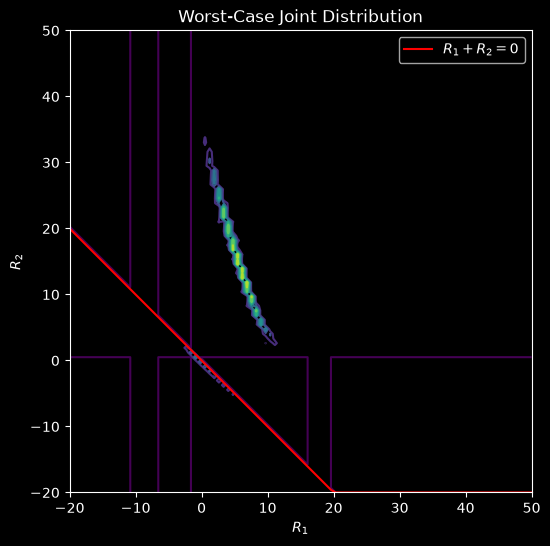

In [5]:
print(f"Worst-case (maximum) probability of a loss {results['worst_case_prob']:.5f}")
print(f"Joint Gaussian probability of a loss {results['gaussian_prob']:.5f}")

R1, R2 = results["R1_grid"], results["R2_grid"]
P_opt = results["joint_distribution"]

plt.figure(figsize=(6,6))
plt.axes().set_aspect('equal')
plt.contour(R1, R2, P_opt)
plt.plot(r, list(map(lambda x: max(x,-20), -r)), color="r", label="$R_1 + R_2 = 0$")
plt.title("Worst-Case Joint Distribution")
plt.xlabel("$R_1$")
plt.ylabel("$R_2$")
plt.legend()
plt.show()

### Experimental Results and Conceptual Analysis

**Severe Distortion from Normality**: The worst-case joint distribution does not resemble the smooth, elliptical contours of a standard bivariate Gaussian distribution. The solver has distorted the shape to maximize the objective function.

**Probability Concentration on the Boundary**:  There is a tight clustering of probability mass directly along the red line, which represents the loss threshold ($R_1 + R_2 = 0$). The optimization algorithm strategically pulled as much probability as possible directly into this specific region to maximize the chance of a loss. Crucially, the mass "sticks" strictly to this boundary rather than moving deeper into the negative region due to the mechanics of the Linear Programming constraints. The objective function is "blind" to the severity of the loss; it equally rewards any probability mass that satisfies $R_1 + R_2 \le 0$. However, shifting probability mass far away from the natural means ($\mu_1=5, \mu_2=15$) is mathematically "expensive" because it severely disrupts the required marginal distributions and the covariance balance ($\rho = -0.3$). Therefore, the solver finds the perfect mathematical compromise: it satisfies the loss condition by placing the mass exactly on the boundary, achieving the maximum possible objective value with the minimum required disruption to the constraints.

**Abnormal Tail Behavior**: In order to push mass into the loss region while still strictly satisfying the given marginal distributions and the correlation constraint, the solver had to compensate by spreading the remaining probability mass into the extreme corners and edges of the grid.

**Underestimation of Tail Risk**: While the Joint Gaussian assumption yields a relatively low loss probability of $\approx 1.8\%$, the worst-case distribution visually demonstrates that the actual risk can be drastically higher if we drop the assumption of joint normality. This illustrates that knowing only the individual asset distributions and their correlation is not enough to accurately assess extreme tail risks.